In [ ]:
#1
from google.colab import files
import pandas as pd

subido = files.upload()  # selecciona tu archivo .xlsx
nombre_archivo = list(subido.keys())[0]

df = pd.read_excel(nombre_archivo)

print(df.head())
print(df.columns.tolist())


Saving Humedad relativa.xlsx to Humedad relativa (1).xlsx
                Fecha  Estacion  Sensor 
0 2026-10-02 14:24:52      73.2       66
1 2026-10-02 14:29:52      73.6       64
2 2026-10-02 14:34:52      73.1       63
3 2026-10-02 14:39:52      72.5       65
4 2026-10-02 14:44:52      72.8       59
['Fecha', 'Estacion', 'Sensor ']


In [ ]:
#2
col_fecha  = "Fecha"         # columna de fecha
col_sensor = "Sensor "        # humedad del sensor (variable X)
col_ref    = "Estacion"      # humedad de la estación = referencia (variable Y)

datos = df[[col_fecha, col_sensor, col_ref]].copy()
datos[col_fecha]  = pd.to_datetime(datos[col_fecha], errors="coerce")
datos[col_sensor] = pd.to_numeric(datos[col_sensor], errors="coerce")
datos[col_ref]    = pd.to_numeric(datos[col_ref], errors="coerce")

datos = datos.dropna().sort_values(col_fecha).reset_index(drop=True)
print(f"Datos válidos: {len(datos)} de {len(df)}")

Datos válidos: 289 de 289


In [ ]:
#3
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

X = datos[[col_sensor]].values
y = datos[col_ref].values

# Separar entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modelo = LinearRegression()
modelo.fit(X_train, y_train)

pendiente = modelo.coef_[0]
intercepto = modelo.intercept_
print(f"Ecuación de corrección: Valor_corregido = {pendiente:.4f} * Sensor + {intercepto:.4f}")

# Métricas
y_pred = modelo.predict(X_test)
print(f"R²   : {r2_score(y_test, y_pred):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"MAE  : {mean_absolute_error(y_test, y_pred):.4f}")

# Error antes de corregir (sensor vs estación)
rmse_antes = np.sqrt(mean_squared_error(y_test, X_test.ravel()))
print(f"RMSE sin corregir: {rmse_antes:.4f}")

Ecuación de corrección: Valor_corregido = 0.6344 * Sensor + 32.8134
R²   : 0.6254
RMSE : 3.7753
MAE  : 3.1950
RMSE sin corregir: 4.7736


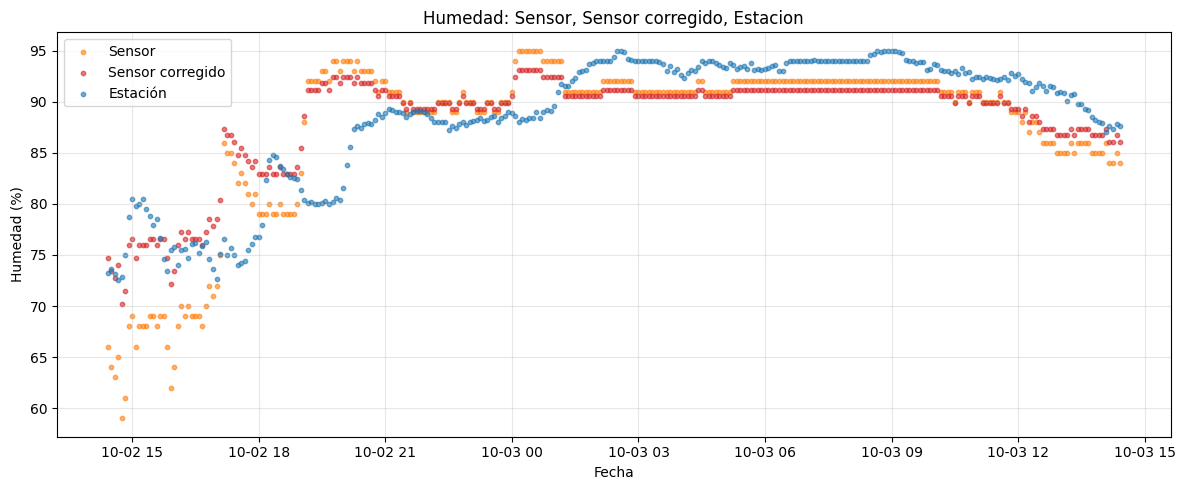

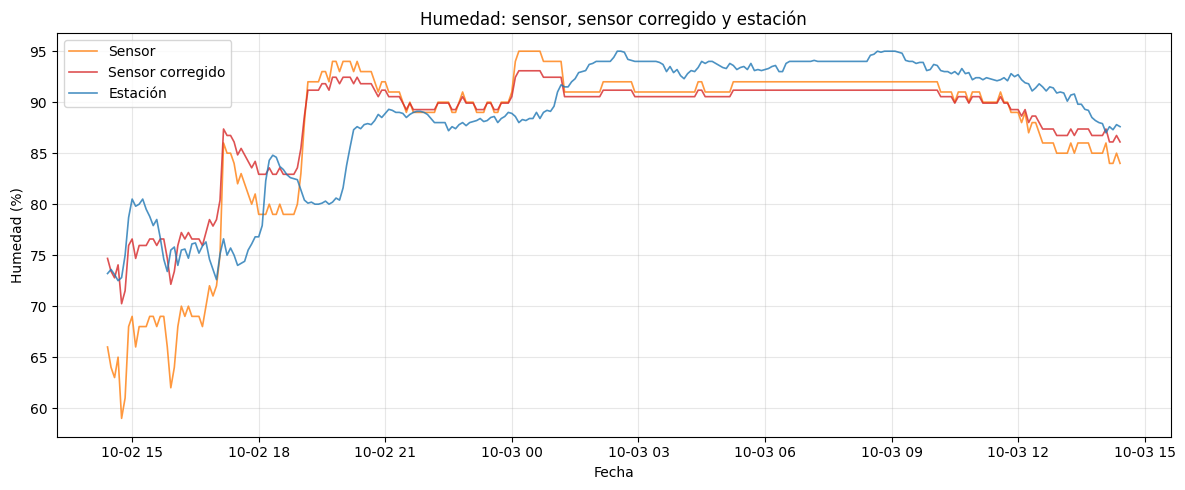

In [ ]:
import matplotlib.pyplot as plt

# Aplicar la corrección al sensor
datos["Sensor_corregido"] = modelo.predict(datos[[col_sensor]].values)

fecha = datos[col_fecha]

# 1) Sensores y estacion puntos
plt.figure(figsize=(12, 5))
plt.scatter(fecha, datos[col_sensor], s=10, alpha=0.6, label="Sensor", color="tab:orange")
plt.scatter(fecha, datos["Sensor_corregido"], s=10, alpha=0.6, label="Sensor corregido", color="tab:red")
plt.scatter(fecha, datos[col_ref], s=10, alpha=0.6, label="Estación", color="tab:blue")
plt.title("Humedad: Sensor, Sensor corregido, Estacion")
plt.xlabel("Fecha")
plt.ylabel("Humedad (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Sensor, sensor corregido y estación (con línea)
plt.figure(figsize=(12, 5))
plt.plot(fecha, datos[col_sensor], label="Sensor", color="tab:orange", linewidth=1.2, alpha=0.8)
plt.plot(fecha, datos["Sensor_corregido"], label="Sensor corregido", color="tab:red", linewidth=1.2, alpha=0.8)
plt.plot(fecha, datos[col_ref], label="Estación", color="tab:blue", linewidth=1.2, alpha=0.8)
plt.title("Humedad: sensor, sensor corregido y estación")
plt.xlabel("Fecha")
plt.ylabel("Humedad (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#5
df["Sensor_corregido"] = modelo.predict(
    df[[col_sensor]].apply(pd.to_numeric, errors="coerce").fillna(df[col_sensor].mean())
)

df.to_excel("regresion_lineal_simple_datos_corregidos.xlsx", index=False)
files.download("regresion_lineal_simple_datos_corregidos.xlsx")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>